# 05 · Spark MLlib: EV-share forecast and state groups (E4)

**Part A · Forecast.** *"What share of next month's new vehicles in each state will be electric?"*
- One row = one **state × vehicle type (T / NT) × month**. Label = EV share in % (0–100).
- Features = what we already know at the start of that month: the EV share 1, 2, 3 and 12 months ago, the 3-month average, the calendar month, the trend (months since 2020), Transport or not, state size, region.
- **Time-respecting split** (never let the model see the future):

| Stage | Train on | Check on | Purpose |
|---|---|---|---|
| choose settings | 2021–2024 | **2025** (validation) | pick the best settings of each model |
| final test | 2021–2025 | **2026** Jan–Sep (test) | honest score on months the model never saw |

- Three MLlib models (Linear regression, Random forest, Gradient-boosted trees) against two simple guesses (**baselines**):
  - *same month last year* (the baseline in our proposal)
  - *last month* (a tougher baseline: "next month looks like this month")
- Scores in **percentage points**: RMSE (big misses count more), MAE (average miss), R².

**Part B · State groups.** KMeans clustering of the 36 states/UTs on EV adoption, growth, two-wheeler share and road safety. The silhouette score picks the number of groups.

Run top to bottom: about 3–6 minutes. Charts are saved in `IAIP\reports\figures\` for the report and the video.

## Step 1 · Start Spark and load Gold

In [1]:
import os, sys, math, shutil
from pathlib import Path
from datetime import date

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StringIndexer, OneHotEncoder, StandardScaler, Imputer, PCA
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import RegressionEvaluator, ClusteringEvaluator
from pyspark.ml.functions import vector_to_array

spark = (SparkSession.builder.appName("IAIP-05-MLlib").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").config("spark.sql.ansi.enabled", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

BASE = Path.cwd().parent
WH, G = BASE / "warehouse", BASE / "warehouse" / "gold"
FIG = BASE / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
for t in ["ev_share_state_month", "dim_state", "state_profile_latest", "category_growth"]:
    spark.read.parquet((G / t).as_uri()).createOrReplaceTempView(t)

import matplotlib
import matplotlib.pyplot as plt
print("Spark", spark.version, "| figures ->", FIG)

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.2.0 | figures -> c:\Users\Arka\Desktop\IAIP\reports\figures


## Step 2 · Build the features

`lag(k)` = the EV share *k* months earlier for the same state and vehicle type (a **window function**, like in Gold).
We drop the partial month (Oct 2026), and the first 12 months (2020) because they have no 12-month lag.
Tiny cells (fewer than 100 registrations in the month) are left out of training and scoring: there, 1 extra EV moves the share by 1% or more, which is noise.

In [2]:
es = spark.sql("""
    SELECT e.state_code, e.vehicle_type, e.month_date, e.year, e.month,
           e.total_registrations, e.ev_share_pct AS ev_share, s.region
    FROM ev_share_state_month e JOIN dim_state s ON e.state_code = s.state_code
    WHERE e.vehicle_type IN ('T', 'NT') AND NOT e.is_partial_month
""")

w = Window.partitionBy("state_code", "vehicle_type").orderBy("month_date")
feat = es
for k in [1, 2, 3, 12]:
    feat = feat.withColumn(f"lag{k}", F.lag("ev_share", k).over(w))
size = (es.filter("year = 2024").groupBy("state_code", "vehicle_type")
          .agg(F.log10(F.sum("total_registrations") + 1).alias("log_size")))      # state size, known before 2025
feat = (feat.join(size, ["state_code", "vehicle_type"], "left")
            .withColumn("roll3", (F.col("lag1") + F.col("lag2") + F.col("lag3")) / 3)
            .withColumn("t", (F.col("year") - 2020) * 12 + F.col("month") - 1)
            .withColumn("is_T", (F.col("vehicle_type") == "T").cast("double"))
            .withColumn("month", F.col("month").cast("double"))).cache()

NUM_FEATURES = ["lag1", "lag2", "lag3", "lag12", "roll3", "month", "t", "is_T", "log_size"]
usable = feat.dropna(subset=NUM_FEATURES + ["ev_share"]).filter("total_registrations >= 100")

fit_train = usable.filter("year BETWEEN 2021 AND 2024")
val       = usable.filter("year = 2025")
train     = usable.filter("year BETWEEN 2021 AND 2025")
test      = usable.filter("year = 2026")
for name, d in [("fit_train (2021-24)", fit_train), ("validation (2025)", val), ("train (2021-25)", train), ("test (2026)", test)]:
    print(f"{name:20} {d.count():>6,} rows")
usable.select("state_code", "vehicle_type", "month_date", "ev_share", "lag1", "lag12", "roll3").orderBy(F.desc("month_date")).show(5)

fit_train (2021-24)   3,241 rows
validation (2025)       824 rows
train (2021-25)       4,065 rows
test (2026)             694 rows
+----------+------------+----------+--------+------+------+------------------+
|state_code|vehicle_type|month_date|ev_share|  lag1| lag12|             roll3|
+----------+------------+----------+--------+------+------+------------------+
|        CG|          NT|2026-10-01|   8.513| 9.516| 3.572| 9.805666666666667|
|        DL|          NT|2026-10-01|  11.909|14.261| 5.742|13.369666666666667|
|        TG|           T|2026-10-01|  15.427|14.491| 5.093|14.693666666666665|
|        MN|          NT|2026-10-01|   3.004| 0.966| 1.601|1.3630000000000002|
|        MN|           T|2026-10-01|  69.588|38.318|50.935|30.579666666666668|
+----------+------------+----------+--------+------+------+------------------+
only showing top 5 rows


## Step 3 · An MLlib **Pipeline**

A Pipeline is an assembly line, the same idea as in the lessons:
1. `StringIndexer` turns the region name into a number, 2. `OneHotEncoder` turns that number into 0/1 columns (no fake order between regions),
3. `VectorAssembler` packs all features into one `features` column, 4. the model learns.

`fit()` runs the whole line on training data and returns a *PipelineModel* that can `transform()` any new month in exactly the same way.

In [3]:
def make_pipeline(model):
    return Pipeline(stages=[
        StringIndexer(inputCol="region", outputCol="region_idx", handleInvalid="keep"),
        OneHotEncoder(inputCol="region_idx", outputCol="region_vec"),
        VectorAssembler(inputCols=NUM_FEATURES + ["region_vec"], outputCol="features", handleInvalid="skip"),
        model])

def scores(df, pred_col):
    ev = RegressionEvaluator(labelCol="ev_share", predictionCol=pred_col)
    return {m: round(ev.setMetricName(m).evaluate(df), 4) for m in ["rmse", "mae", "r2"]}

L = dict(featuresCol="features", labelCol="ev_share")
CANDIDATES = {
    "Linear regression":      [LinearRegression(**L, regParam=r, elasticNetParam=0.0) for r in (0.0, 0.1)],
    "Random forest":          [RandomForestRegressor(**L, numTrees=100, maxDepth=d, seed=231) for d in (5, 8)],
    "Gradient-boosted trees": [GBTRegressor(**L, maxIter=n, maxDepth=d, seed=231) for n, d in ((60, 3), (100, 5))],
}

## Step 4 · Choose settings on 2025 (validation), never on the test year

In [4]:
best = {}
for family, options in CANDIDATES.items():
    for est in options:
        settings = {p.name: est.getOrDefault(p) for p in est.params if p.name in ("regParam", "numTrees", "maxDepth", "maxIter")}
        s = scores(make_pipeline(est).fit(fit_train).transform(val), "prediction")
        print(f"{family:24} {str(settings):40} validation RMSE {s['rmse']:.3f}")
        if family not in best or s["rmse"] < best[family][1]["rmse"]:
            best[family] = (est, s, settings)

CHOSEN = min(best, key=lambda f: best[f][1]["rmse"])
print("\nchosen on validation:", CHOSEN, best[CHOSEN][2])

Linear regression        {'maxIter': 100, 'regParam': 0.0}        validation RMSE 3.206
Linear regression        {'maxIter': 100, 'regParam': 0.1}        validation RMSE 3.216
Random forest            {'maxDepth': 5, 'numTrees': 100}         validation RMSE 3.753
Random forest            {'maxDepth': 8, 'numTrees': 100}         validation RMSE 3.664
Gradient-boosted trees   {'maxDepth': 3, 'maxIter': 60}           validation RMSE 4.056
Gradient-boosted trees   {'maxDepth': 5, 'maxIter': 100}          validation RMSE 4.066

chosen on validation: Linear regression {'maxIter': 100, 'regParam': 0.0}


## Step 5 · Final test on 2026 (Jan–Sep)

Every model is re-trained on 2021–2025 with its chosen settings and scored on 2026, a year it has never seen. The two baselines need no training: their "prediction" is simply `lag12` (same month last year) and `lag1` (last month).

In [5]:
results, models, test_pred = [], {}, None
for family, (est, _, settings) in best.items():
    m = make_pipeline(est).fit(train)
    models[family] = m
    p = m.transform(test)
    results.append((family, str(settings), *scores(p, "prediction").values()))
    if family == CHOSEN:
        test_pred = p.withColumn("pred_model", F.greatest(F.lit(0.0), F.least(F.lit(100.0), F.col("prediction"))))
for name, col in [("Baseline: same month last year", "lag12"), ("Baseline: last month", "lag1")]:
    results.append((name, "-", *scores(test, col).values()))

comparison = spark.createDataFrame(results, "model string, settings string, rmse double, mae double, r2 double").orderBy("rmse")
comparison.show(truncate=False)

+------------------------------+---------------------------------+------+------+------+
|model                         |settings                         |rmse  |mae   |r2    |
+------------------------------+---------------------------------+------+------+------+
|Linear regression             |{'maxIter': 100, 'regParam': 0.0}|3.3683|1.7838|0.9675|
|Baseline: last month          |-                                |3.4777|1.7939|0.9653|
|Random forest                 |{'maxDepth': 8, 'numTrees': 100} |3.7552|2.0574|0.9596|
|Gradient-boosted trees        |{'maxDepth': 3, 'maxIter': 60}   |3.8401|2.0601|0.9577|
|Baseline: same month last year|-                                |6.3141|3.4046|0.8857|
+------------------------------+---------------------------------+------+------+------+



### Which features did the trees use most?

In [6]:
tree_family = CHOSEN if CHOSEN != "Linear regression" else "Gradient-boosted trees"
tm = models[tree_family]
attrs = test_pred.schema["features"].metadata["ml_attr"]["attrs"]
names = sorted([a for group in attrs.values() for a in group], key=lambda a: a["idx"])
imp = tm.stages[-1].featureImportances.toArray()
top = sorted(zip([n["name"] for n in names], imp), key=lambda x: -x[1])
print(f"Feature importance ({tree_family}):")
for n, v in top[:8]:
    print(f"  {n:22} {v:6.3f}  " + "#" * int(v * 60))

Feature importance (Gradient-boosted trees):
  roll3                   0.808  ################################################
  lag1                    0.074  ####
  month                   0.025  #
  t                       0.024  #
  lag3                    0.017  
  lag12                   0.016  
  lag2                    0.014  
  log_size                0.014  


## Step 6 · Forecast the next 3 months (Oct–Dec 2026)

To forecast 2 or 3 months ahead we need lag values that have not happened yet, so we use the model's own forecast as the "last month" for the next step (**recursive forecasting**). Errors add up step by step, so the 3rd month is the least certain.

In [7]:
def add_m(d, k):
    y, m = divmod(d.month - 1 + k, 12)
    return date(d.year + y, m + 1, 1)

best_model = models[CHOSEN]
hist = feat.select("state_code", "vehicle_type", "month_date", "ev_share")
static = feat.select("state_code", "vehicle_type", "region", "is_T", "log_size").distinct()
last = feat.agg(F.max("month_date")).first()[0]
steps = []
for k_ahead in (1, 2, 3):
    m = add_m(last, k_ahead)
    f = static
    for k in (1, 2, 3, 12):
        f = f.join(hist.filter(F.col("month_date") == F.lit(add_m(m, -k)))
                       .select("state_code", "vehicle_type", F.col("ev_share").alias(f"lag{k}")),
                   ["state_code", "vehicle_type"], "left")
    f = (f.withColumn("roll3", (F.col("lag1") + F.col("lag2") + F.col("lag3")) / 3)
          .withColumn("month", F.lit(float(m.month))).withColumn("t", F.lit((m.year - 2020) * 12 + m.month - 1))
          .withColumn("month_date", F.lit(m)))
    out = (best_model.transform(f)
           .select("state_code", "vehicle_type", "month_date",
                   F.greatest(F.lit(0.0), F.least(F.lit(100.0), F.col("prediction"))).alias("ev_share"))
           .localCheckpoint())
    hist = hist.unionByName(out)
    steps.append(out.withColumn("months_ahead", F.lit(k_ahead)))
future = steps[0].unionByName(steps[1]).unionByName(steps[2])

# weight each state's forecast by its registrations in the same month of 2025 -> All-India forecast
weights = feat.filter("year = 2025").select("state_code", "vehicle_type", "month", "total_registrations")
future = (future.withColumn("month", F.month("month_date").cast("double"))
                .join(weights, ["state_code", "vehicle_type", "month"], "left").drop("month"))
print("last complete month:", last, "| forecast months:", [str(add_m(last, k)) for k in (1, 2, 3)])

last complete month: 2026-10-01 | forecast months: ['2026-11-01', '2026-12-01', '2027-01-01']


## Step 7 · Chart: All-India EV share, actual vs forecast

State predictions are added up (weighted by registrations) to get All India, separately for private (NT) and commercial (T) vehicles.

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.p

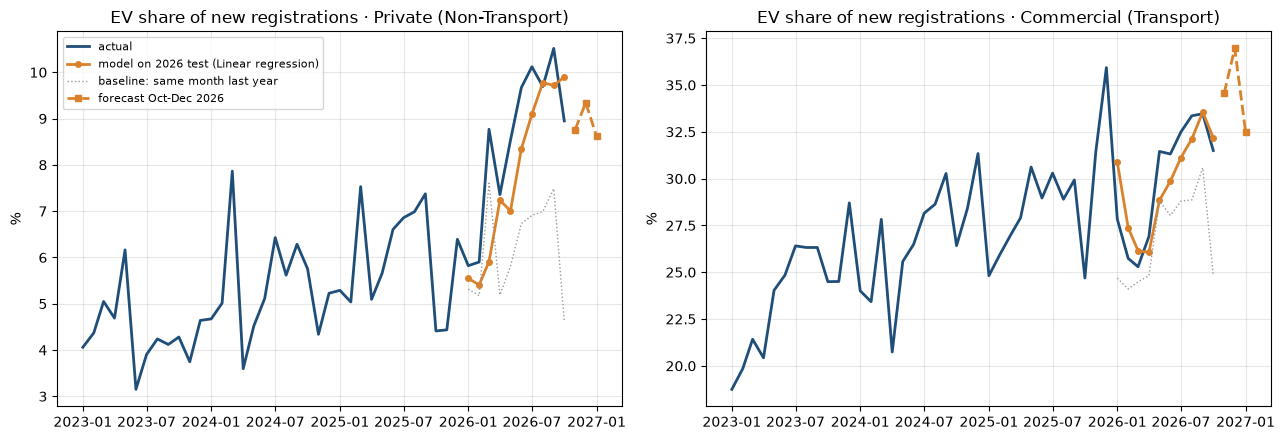

All-India 2026: actual vs model (EV share %)


c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


vehicle_type month_date  share_actual  share_model
           T 2026-01-01         27.84        30.89
          NT 2026-01-01          5.82         5.55
          NT 2026-02-01          5.90         5.41
           T 2026-02-01         25.74        27.38
          NT 2026-03-01          8.77         5.91
           T 2026-03-01         25.30        26.15
           T 2026-04-01         26.93        26.06
          NT 2026-04-01          7.36         7.24
           T 2026-05-01         31.46        28.84
          NT 2026-05-01          8.53         7.01
          NT 2026-06-01          9.67         8.35
           T 2026-06-01         31.32        29.87
          NT 2026-07-01         10.12         9.09
           T 2026-07-01         32.50        31.12
          NT 2026-08-01          9.69         9.78
           T 2026-08-01         33.36        32.12
          NT 2026-09-01         10.52         9.72
           T 2026-09-01         33.47        33.55
           T 2026-10-01        

In [8]:
def india(df, share_col, weight_col="total_registrations"):
    return (df.groupBy("vehicle_type", "month_date")
              .agg((F.sum(F.col(share_col) * F.col(weight_col)) / F.sum(weight_col)).alias("share"))
              .orderBy("month_date").toPandas())

actual = spark.sql("""SELECT vehicle_type, month_date, ev_share_pct AS share FROM ev_share_state_month
                      WHERE state_code = 'IN' AND vehicle_type IN ('T','NT') AND year >= 2023 AND NOT is_partial_month
                      ORDER BY month_date""").toPandas()
tested, ahead = india(test_pred, "pred_model"), india(future, "ev_share")
lastyear = india(test, "lag12")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, vt, title in [(axes[0], "NT", "Private (Non-Transport)"), (axes[1], "T", "Commercial (Transport)")]:
    a, t_, f_, b = (d[d.vehicle_type == vt] for d in (actual, tested, ahead, lastyear))
    ax.plot(a.month_date, a.share, color="#1f4e79", lw=2, label="actual")
    ax.plot(t_.month_date, t_.share, color="#d9822b", lw=2, marker="o", ms=4, label=f"model on 2026 test ({CHOSEN})")
    ax.plot(b.month_date, b.share, color="#999999", lw=1, ls=":", label="baseline: same month last year")
    ax.plot(f_.month_date, f_.share, color="#d9822b", lw=2, ls="--", marker="s", ms=4, label="forecast Oct-Dec 2026")
    ax.set_title(f"EV share of new registrations · {title}")
    ax.set_ylabel("%"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "ml_ev_forecast_india.png", dpi=150); plt.show()

print("All-India 2026: actual vs model (EV share %)")
chk = india(test_pred.withColumn("actual", F.col("ev_share")), "actual").merge(tested, on=["vehicle_type", "month_date"], suffixes=("_actual", "_model"))
print(chk.round(2).to_string(index=False))

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


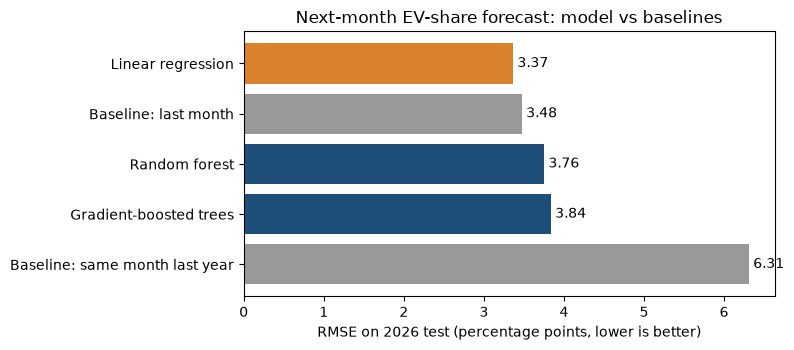

In [9]:
cmp_pd = comparison.toPandas()
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = ["#d9822b" if m == CHOSEN else ("#999999" if m.startswith("Baseline") else "#1f4e79") for m in cmp_pd.model]
ax.barh(cmp_pd.model, cmp_pd.rmse, color=colors)
for y, v in enumerate(cmp_pd.rmse):
    ax.text(v, y, f" {v:.2f}", va="center")
ax.invert_yaxis(); ax.set_xlabel("RMSE on 2026 test (percentage points, lower is better)")
ax.set_title("Next-month EV-share forecast: model vs baselines")
plt.tight_layout(); plt.savefig(FIG / "ml_model_comparison.png", dpi=150); plt.show()

## Step 8 · Part B: group the states (KMeans clustering)

Each state/UT gets 7 numbers. Missing values are filled with the median (`Imputer`), and every column is put on the same scale (`StandardScaler`), otherwise *growth %* would outweigh everything else.

| Feature | Meaning |
|---|---|
| log_registrations_2025 | market size (log scale) |
| growth_2025_pct | registration growth 2024 → 2025 |
| ev_share_2025_private_pct | EV share, private vehicles |
| ev_share_2025_commercial_pct | EV share, commercial vehicles (e-rickshaws, e-buses …) |
| ev_share_gain_2022_2025 | how fast EV share rose (percentage points) |
| two_wheeler_share_2025 | share of two-wheelers in new registrations |
| deaths_per_10k_new_reg_2023 | road deaths per 10,000 new registrations |

We try 3 to 6 groups and keep the number with the best **silhouette** score (−1 to 1: higher = groups are tight and well separated).

In [10]:
states = spark.sql("""
    WITH ev AS (
        SELECT state_code,
               100 * SUM(CASE WHEN year = 2025 THEN ev_registrations END) / SUM(CASE WHEN year = 2025 THEN total_registrations END)
             - 100 * SUM(CASE WHEN year = 2022 THEN ev_registrations END) / SUM(CASE WHEN year = 2022 THEN total_registrations END) AS ev_share_gain_2022_2025
        FROM ev_share_state_month WHERE vehicle_type = 'ALL' AND state_code <> 'IN' GROUP BY state_code),
    tw AS (
        SELECT state_code, 100 * SUM(CASE WHEN category_group = 'Two Wheeler' THEN registrations ELSE 0 END) / SUM(registrations) AS two_wheeler_share_2025
        FROM category_growth WHERE year = 2025 AND vehicle_type = 'ALL' AND state_code <> 'IN' GROUP BY state_code)
    SELECT p.state_code, p.state_name, p.region,
           CAST(log10(p.reg_2025) AS DOUBLE)              AS log_registrations_2025,
           CAST(p.growth_2025_pct AS DOUBLE)              AS growth_2025_pct,
           CAST(p.ev_share_2025_private_pct AS DOUBLE)    AS ev_share_2025_private_pct,
           CAST(p.ev_share_2025_commercial_pct AS DOUBLE) AS ev_share_2025_commercial_pct,
           CAST(ev.ev_share_gain_2022_2025 AS DOUBLE)     AS ev_share_gain_2022_2025,
           CAST(tw.two_wheeler_share_2025 AS DOUBLE)      AS two_wheeler_share_2025,
           CAST(p.deaths_per_10k_new_reg_2023 AS DOUBLE)  AS deaths_per_10k_new_reg_2023
    FROM state_profile_latest p LEFT JOIN ev ON p.state_code = ev.state_code LEFT JOIN tw ON p.state_code = tw.state_code
""").cache()
CL_FEATURES = ["log_registrations_2025", "growth_2025_pct", "ev_share_2025_private_pct", "ev_share_2025_commercial_pct",
               "ev_share_gain_2022_2025", "two_wheeler_share_2025", "deaths_per_10k_new_reg_2023"]
print("states:", states.count(), "| missing values per feature:",
      {c: states.filter(F.col(c).isNull()).count() for c in CL_FEATURES})

def cluster_pipeline(k):
    return Pipeline(stages=[
        Imputer(inputCols=CL_FEATURES, outputCols=[c + "_f" for c in CL_FEATURES], strategy="median"),
        VectorAssembler(inputCols=[c + "_f" for c in CL_FEATURES], outputCol="raw"),
        StandardScaler(inputCol="raw", outputCol="scaled", withMean=True, withStd=True),
        KMeans(featuresCol="scaled", predictionCol="cluster", k=k, seed=231, maxIter=50)])

sil = ClusteringEvaluator(featuresCol="scaled", predictionCol="cluster")
tries = {}
for k in range(3, 7):
    m = cluster_pipeline(k).fit(states)
    tries[k] = (sil.evaluate(m.transform(states)), m)
    print(f"k = {k}: silhouette {tries[k][0]:.3f}")
K = max(tries, key=lambda k: tries[k][0])
cl_model = tries[K][1]
clustered = cl_model.transform(states)
print("chosen number of groups:", K)

states: 36 | missing values per feature: {'log_registrations_2025': 0, 'growth_2025_pct': 0, 'ev_share_2025_private_pct': 0, 'ev_share_2025_commercial_pct': 0, 'ev_share_gain_2022_2025': 0, 'two_wheeler_share_2025': 0, 'deaths_per_10k_new_reg_2023': 0}
k = 3: silhouette 0.354
k = 4: silhouette 0.366
k = 5: silhouette 0.400
k = 6: silhouette 0.287
chosen number of groups: 5


In [11]:
profile = (clustered.groupBy("cluster")
           .agg(F.count("*").alias("n"), *[F.round(F.avg(c), 1).alias(c.replace("_2025", "").replace("_pct", "")) for c in CL_FEATURES],
                F.concat_ws(", ", F.sort_array(F.collect_list("state_code"))).alias("states"))
           .orderBy("cluster"))
profile.show(truncate=False)

+-------+---+-----------------+------+----------------+-------------------+------------------+-----------------+---------------------------+--------------------------------------------------+
|cluster|n  |log_registrations|growth|ev_share_private|ev_share_commercial|ev_share_gain_2022|two_wheeler_share|deaths_per_10k_new_reg_2023|states                                            |
+-------+---+-----------------+------+----------------+-------------------+------------------+-----------------+---------------------------+--------------------------------------------------+
|0      |7  |5.7              |4.7   |3.5             |60.0               |5.7               |68.6             |47.0                       |AS, BR, CH, DL, TR, UP, WB                        |
|1      |1  |3.6              |-21.0 |0.1             |0.0                |-0.6              |11.9             |114.7                      |LA                                                |
|2      |13 |6.0              |7.0   |7.

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


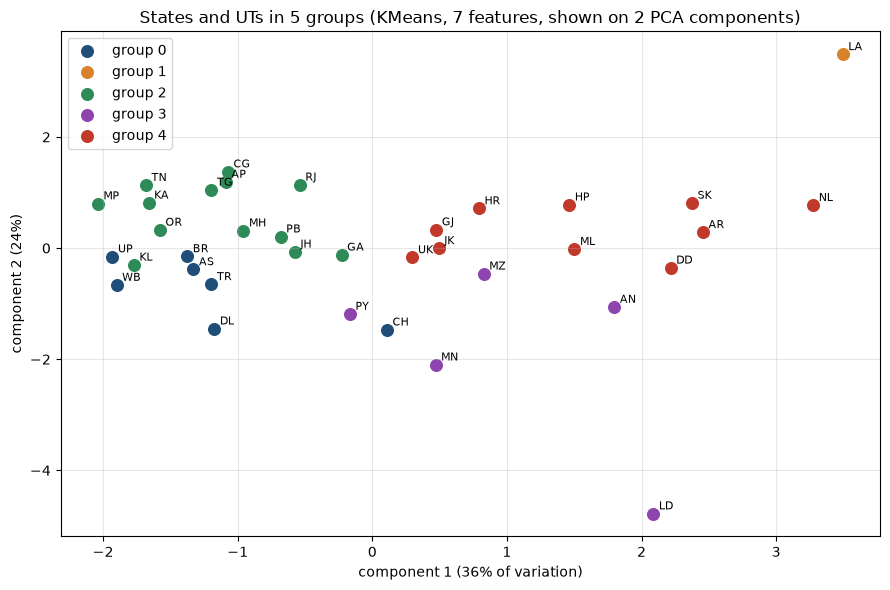

In [12]:
pca_model = PCA(k=2, inputCol="scaled", outputCol="pca").fit(clustered)
pts = (pca_model.transform(clustered).withColumn("pc", vector_to_array("pca"))
       .select("state_code", "state_name", "region", "cluster", F.col("pc")[0].alias("pc1"), F.col("pc")[1].alias("pc2"), *CL_FEATURES))
pp = pts.toPandas()
fig, ax = plt.subplots(figsize=(9, 6))
palette = ["#1f4e79", "#d9822b", "#2e8b57", "#8e44ad", "#c0392b", "#7f8c8d"]
for c in sorted(pp.cluster.unique()):
    d = pp[pp.cluster == c]
    ax.scatter(d.pc1, d.pc2, s=70, color=palette[c % 6], label=f"group {c}")
    for _, r in d.iterrows():
        ax.annotate(r.state_code, (r.pc1, r.pc2), xytext=(4, 3), textcoords="offset points", fontsize=8)
ev = pca_model.explainedVariance.toArray()
ax.set_xlabel(f"component 1 ({100*ev[0]:.0f}% of variation)"); ax.set_ylabel(f"component 2 ({100*ev[1]:.0f}%)")
ax.set_title(f"States and UTs in {K} groups (KMeans, 7 features, shown on 2 PCA components)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "ml_state_groups.png", dpi=150); plt.show()

## Step 9 · Save results to Gold and Power BI

In [13]:
def save(df, name):
    df.write.mode("overwrite").parquet((G / name).as_uri())
    tmp = G / "_tmp_csv" / name
    spark.read.parquet((G / name).as_uri()).coalesce(1).write.mode("overwrite").option("header", True).csv(tmp.as_uri())
    os.replace(next(tmp.glob("part-*.csv")), G / "_powerbi" / f"{name}.csv")
    print(f"gold/{name:28} {spark.read.parquet((G / name).as_uri()).count():>6,} rows (+ Power BI CSV)")

save(test_pred.select("state_code", "vehicle_type", "month_date", "total_registrations",
                      F.round("ev_share", 3).alias("actual_ev_share"), F.round("pred_model", 3).alias("predicted_ev_share"),
                      F.round("lag12", 3).alias("baseline_same_month_last_year"), F.round("lag1", 3).alias("baseline_last_month")),
     "ml_ev_forecast_test")
save(future.select("state_code", "vehicle_type", "month_date", "months_ahead", F.round("ev_share", 3).alias("forecast_ev_share")),
     "ml_ev_forecast_future")
save(comparison.withColumn("chosen_on_validation", F.col("model") == CHOSEN), "ml_model_comparison")
save(pts.withColumn("n_groups", F.lit(K)), "ml_state_groups")
shutil.rmtree(G / "_tmp_csv", ignore_errors=True)

try:
    best_model.write().overwrite().save((WH / "models" / "ev_share_forecast").as_uri())
    cl_model.write().overwrite().save((WH / "models" / "state_groups").as_uri())
    print("models saved in warehouse\\models")
except Exception as e:
    print("model files not saved (results above are still saved):", str(e)[:200])

gold/ml_ev_forecast_test             694 rows (+ Power BI CSV)
gold/ml_ev_forecast_future           216 rows (+ Power BI CSV)
gold/ml_model_comparison               5 rows (+ Power BI CSV)
gold/ml_state_groups                  36 rows (+ Power BI CSV)
models saved in warehouse\models


## Step 10 · E4 summary

In [14]:
c = {r["model"]: r for r in comparison.collect()}
m, b12, b1 = c[CHOSEN], c["Baseline: same month last year"], c["Baseline: last month"]
print(f"Chosen model (on 2025 validation): {CHOSEN}")
print(f"2026 test RMSE: model {m['rmse']:.2f} pp | same-month-last-year {b12['rmse']:.2f} pp | last-month {b1['rmse']:.2f} pp")
print(f"Improvement over the proposal baseline: {100*(1 - m['rmse']/b12['rmse']):.0f}% lower RMSE")
print(f"Improvement over the last-month baseline: {100*(1 - m['rmse']/b1['rmse']):.0f}% lower RMSE")
print(f"State groups: k = {K}, silhouette {tries[K][0]:.3f}")

Chosen model (on 2025 validation): Linear regression
2026 test RMSE: model 3.37 pp | same-month-last-year 6.31 pp | last-month 3.48 pp
Improvement over the proposal baseline: 47% lower RMSE
Improvement over the last-month baseline: 3% lower RMSE
State groups: k = 5, silhouette 0.400


In [15]:
spark.stop()
print("stream and Spark stopped")

stream and Spark stopped
